<a href="https://colab.research.google.com/github/aarushi18anand-ux/IHDS-analysis/blob/main/IHDS_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Household Spending and Children's Learning in Northern India
**Data** by India Human Development Survey-II (IHDS-II), 2011-12 (ICPSR 36151)

Analysis by **Aarushi Anand**

**Question:** How strongly are reading and maths levels of children aged 8-11 in northern India related to their household's spending?

**Plan:** (1) load and understand the data, (2) check missing values, (3) compare richer and poorer households, (4) run regression models, (5) interpret the results.

**Note:** this analysis describes associations. It cannot show that spending *causes* higher scores.

In [25]:
## mounting google drive
from google.colab import drive
drive.mount("/content/drive")



MessageError: Error: credential propagation was unsuccessful

In [45]:
## importing libraries used in this analysis
import pandas as pd               ## tables and opening the data
import numpy as np                ## maths (logs, averages)
import matplotlib.pyplot as plt   ## drawing figures
import seaborn as sns             ## drawing figures
import statsmodels.api as smf     ## regression models used in results

In [12]:
## storing data files' path as stings in variables
file_individual = "/content/drive/MyDrive/Colab Notebooks/36151-0001-Data.dta"
file_household = "/content/drive/MyDrive/Colab Notebooks/36151-0002-Data.dta"

In [26]:
## opening the stata file, keeping only 10 columns we'll be needing
df = pd.read_stata(file_individual,convert_categoricals=False, columns=["STATEID", "IDPSU", "RO3", "RO5", "URBAN2011", "COPC", "GROUPS", "CS4", "TA8B", "TA9B"])
df.shape

(204569, 10)

In [56]:
## renaming the columns to a more comprehensible format
df = df.rename(columns= {"STATEID": "state", "IDPSU": "village", "RO3": "sex", "RO5": "age",
    "URBAN2011": "urban", "COPC": "spending", "GROUPS": "caste",
    "CS4": "school_type", "TA8B": "reading", "TA9B": "math"})

## state number to states
North = {1: "Jammu & Kashmir", 2: "Himachal Pradesh", 3: "Punjab", 4: "Chandigarh",
         5: "Uttarakhand", 6: "Haryana", 7: "Delhi", 8: "Rajasthan", 9: "Uttar Pradesh"}

## keeping children between 8-11
kids = df[df["age"].between(8,11) & df["state"].isin(North)].copy()

## New columns: state name, and 1 = girl / 0 = boy
kids["state_name"] = kids["state"].map(North)
kids["female"] = (kids["sex"] == 2).astype(int)

## checking
print("Children:", len(kids))
print("Villages:", kids["village"].nunique())
kids["state_name"].value_counts()

kids.shape


Children: 5593
Villages: 744


(5593, 12)

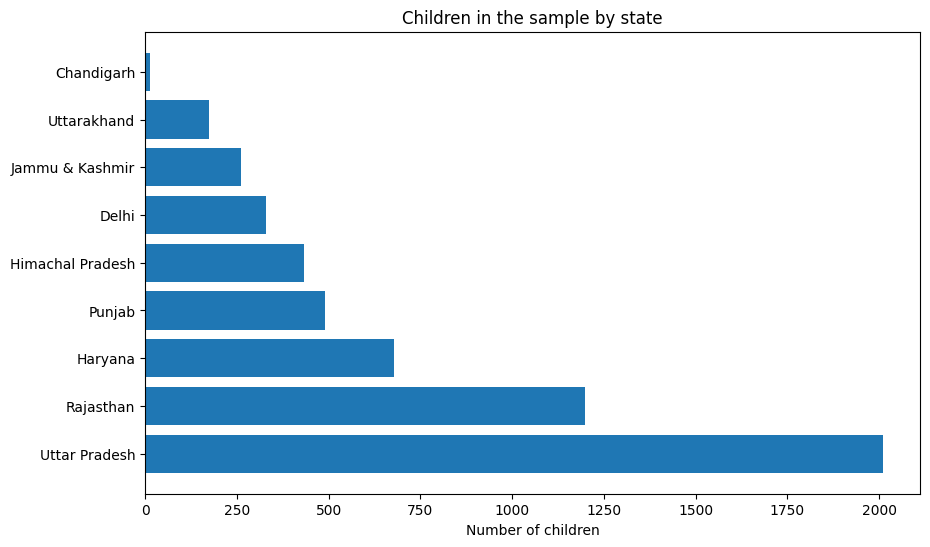

In [62]:
## Counting children per state and draw a horizontal bar chart
state_counts = kids["state_name"].value_counts()

plt.figure(figsize=(10, 6))
plt.barh(state_counts.index, state_counts.values)
plt.xlabel("Number of children")
plt.title("Children in the sample by state")
plt.show()

In [68]:
## Lookup lists: test code -> what the child could do

READ = {0: "0 Cannot read", 1: "1 Letters", 2: "2 Words", 3: "3 Paragraph", 4: "4 Story"}
MATH = {0: "0 Cannot recognise numbers", 1: "1 Numbers", 2: "2 Subtraction", 3: "3 Division"}

## share of children with each level in percentages
reading_pct = kids["reading"].map(READ).value_counts(normalize=True).sort_index() * 100
math_pct = kids["math"].map(MATH).value_counts(normalize=True).sort_index() * 100

print(reading_pct.round(2))
print(math_pct.round(2))


reading
0 Cannot read    13.74
1 Letters        13.33
2 Words          14.92
3 Paragraph      14.47
4 Story          43.54
Name: proportion, dtype: float64
math
0 Cannot recognise numbers    18.45
1 Numbers                     31.42
2 Subtraction                 27.06
3 Division                    23.07
Name: proportion, dtype: float64


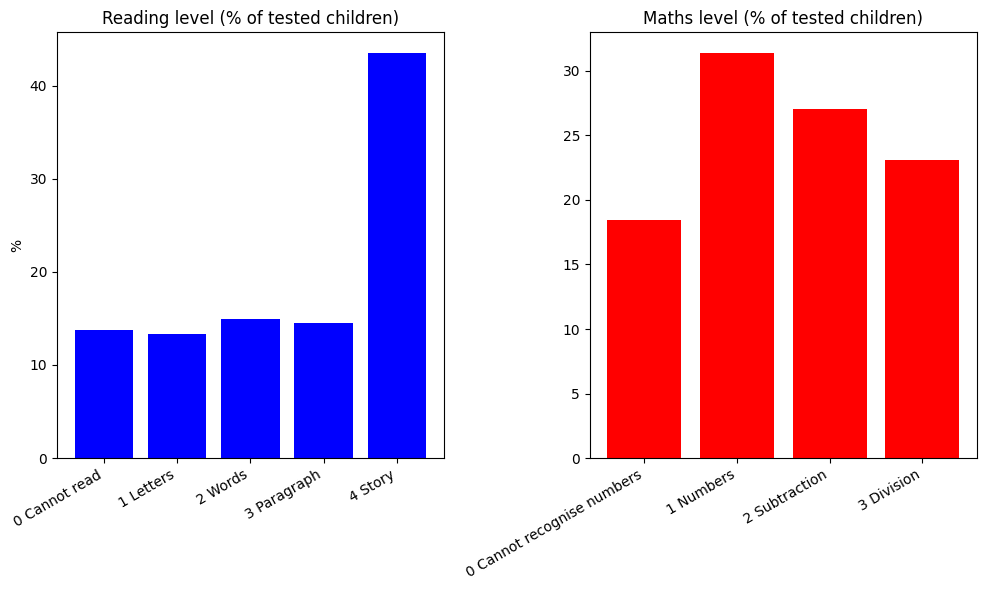

In [78]:
# Two bar charts: share of children at each reading level and maths level
fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].bar(reading_pct.index, reading_pct.values, color="blue")
axes[0].set_title("Reading level (% of tested children)")
axes[0].set_ylabel("%")

axes[1].bar(math_pct.index, math_pct.values, color="red")
axes[1].set_title("Maths level (% of tested children)")

for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")   # tilt long labels

plt.tight_layout()
plt.show()

In [81]:
## True if the child has BOTH a reading and a maths result
kids["tested"] = kids["reading"].notna() & kids["math"].notna()

## four spending groups (log of spending), poorest to richest
kids["quartile"] = pd.qcut(np.log(kids["spending"]), 4,
                           labels=["Q1 poorest", "Q2", "Q3", "Q4 richest"])

print("Share with both tests:", round(kids["tested"].mean(), 3))
print(kids.groupby("quartile", observed=True)["tested"].mean().round(3))
print(kids.groupby("female")["tested"].mean().round(3))

Share with both tests: 0.832
quartile
Q1 poorest    0.813
Q2            0.845
Q3            0.852
Q4 richest    0.818
Name: tested, dtype: float64
female
0    0.833
1    0.830
Name: tested, dtype: float64


In [84]:
## Making a z-score function
def zscore(s):
    return (s - s.mean()) / s.std()

## Standardised spending (log first, because spending is very skewed)
kids["spending_z"] = zscore(np.log(kids["spending"]))

## Standardised test levels (children without a test are skipped automatically)
kids["reading_z"] = zscore(kids["reading"])
kids["math_z"] = zscore(kids["math"])

## Yes/no outcomes that are easy to explain: 1 = yes, 0 = no, blank = not tested
kids["reads_story"] = np.where(kids["reading"].isna(), np.nan, (kids["reading"] == 4).astype(float))
kids["can_subtract"] = np.where(kids["math"].isna(), np.nan, (kids["math"] >= 2).astype(float))

## Yes/no for private school (school type 4); blank if school type is missing
kids["private"] = np.where(kids["school_type"].isna(), np.nan, (kids["school_type"] == 4).astype(float))

## Where do the quartile cut-points fall, in rupees per person?
kids["spending"].quantile([0.25, 0.5, 0.75]).round(2)

,spending
0.25,11331.43
0.50,16227.83
0.75,24755.62


In [85]:
## Averaging of each measure within each wealth group
summary = kids.groupby("quartile", observed=True)[
    ["math_z", "reading_z", "reads_story", "can_subtract", "private", "urban"]].mean()

## Turning the yes/no shares into percentages
pct_cols = ["reads_story", "can_subtract", "private", "urban"]
summary[pct_cols] = summary[pct_cols] * 100

## Adding the number of children in each group
summary["children"] = kids.groupby("quartile", observed=True).size()

summary.round(2)

,math_z,reading_z,reads_story,can_substract,private,urban,children
quartile,,,,,,,
Q1 poorest,-0.44,-0.40,30.12,30.43,30.48,15.23,1399
Q2,-0.15,-0.10,38.78,42.31,39.72,23.41,1397
Q3,0.12,0.09,46.44,55.84,52.32,31.19,1398
Q4 richest,0.47,0.40,58.75,71.85,69.28,45.92,1398


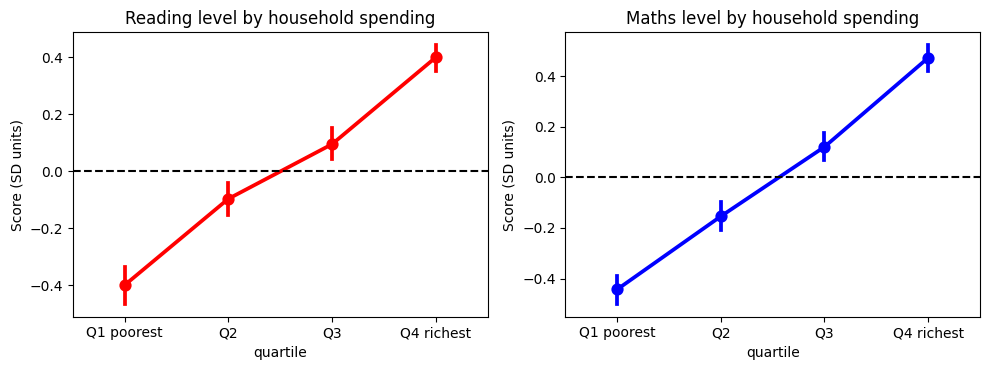

In [91]:
## Picture: average score by wealth group, with 95% confidence bars
reading_data = kids.dropna(subset=["reading_z"])
math_data = kids.dropna(subset=["math_z"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

sns.pointplot(data=reading_data, x="quartile", y="reading_z",
              errorbar=("ci", 95), color="red", ax=axes[0])
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Reading level by household spending")
axes[0].set_ylabel("Score (SD units)")

sns.pointplot(data=math_data, x="quartile", y="math_z",
              errorbar=("ci", 95), color="blue", ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Maths level by household spending")
axes[1].set_ylabel("Score (SD units)")

plt.tight_layout()
plt.show()

In [93]:
## Gap between the richest and poorest quarter, plus a 95% range using "bootstrapping"
def quartile_gap(data, outcome, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)                       # random number generator

    # Scores of children in the poorest and richest groups (blanks dropped)
    # Separate the poorest and richest children
    poorest = data[data["quartile"] == "Q1 poorest"]
    richest = data[data["quartile"] == "Q4 richest"]

## Selecting their scores and remove missing values
    q1 = poorest[outcome].dropna()
    q4 = richest[outcome].dropna()

## Calculating the difference in average scores
    gap = q4.mean() - q1.mean()

    ## Repeating 1,000 times: re-draw children with replacement, recompute the gap
    bootstrap_gaps = []

    for i in range(1000):
        sample_rich = rng.choice(q4, size=len(q4), replace=True)
        sample_poor = rng.choice(q1, size=len(q1), replace=True)

        difference = sample_rich.mean() - sample_poor.mean()
        bootstrap_gaps.append(difference)

    # The middle 95% of those 1,000 gaps is our confidence range
    lower = np.percentile(bootstrap_gaps, 2.5)
    upper = np.percentile(bootstrap_gaps, 97.5)

    return gap, lower, upper

for outcome in ["math_z", "reading_z"]:
    gap, lo, hi = quartile_gap(kids, outcome)
    print(f"{outcome}: gap = {gap:.2f} SD (95% CI {lo:.2f} to {hi:.2f})")

math_z: gap = 0.92 SD (95% CI 0.84 to 0.99)
reading_z: gap = 0.80 SD (95% CI 0.72 to 0.87)


In [48]:
# A helper that fits one regression, with standard errors clustered by village
import statsmodels.formula.api as smf

def fit_model(formula, data, outcome, needed):
    d = data.dropna(subset=[outcome] + needed + ["village"])   # drop rows with blanks
    return smf.ols(formula, data=d).fit(cov_type="cluster",
                                        cov_kwds={"groups": d["village"]})

# First, ONE model on its own so you can read the full output table
demo = fit_model("math_z ~ spending_z + female + age + urban",
                 kids, "math_z", ["spending_z", "female", "age", "urban"])
print(demo.summary())

                            OLS Regression Results                            
Dep. Variable:                 math_z   R-squared:                       0.165
Model:                            OLS   Adj. R-squared:                  0.164
Method:                 Least Squares   F-statistic:                     180.8
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          1.65e-107
Time:                        09:38:56   Log-Likelihood:                -6186.1
No. Observations:                4656   AIC:                         1.238e+04
Df Residuals:                    4651   BIC:                         1.241e+04
Df Model:                           4                                         
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.6744      0.113    -14.786      0.0

In [50]:
# Now three versions of the model, for both maths and reading
results = []
for outcome, label in [("math_z", "Maths"), ("reading_z", "Reading")]:
    specs = {
        "A: spending only":     (f"{outcome} ~ spending_z",
                                 ["spending_z"]),
        "B: + sex, age, urban": (f"{outcome} ~ spending_z + female + age + urban",
                                 ["spending_z", "female", "age", "urban"]),
        "C: B + state":         (f"{outcome} ~ spending_z + female + age + urban + C(state_name)",
                                 ["spending_z", "female", "age", "urban", "state_name"]),
    }
    for name, (formula, needed) in specs.items():
        m = fit_model(formula, kids, outcome, needed)
        lo, hi = m.conf_int().loc["spending_z"]
        results.append({"outcome": label, "model": name, "effect": m.params["spending_z"],
                        "ci_low": lo, "ci_high": hi, "n": int(m.nobs)})


In [51]:
# Yes/no outcomes: the coefficient becomes "percentage points"
rows = []
for outcome, label in [("reads_story", "Can read a story"),
                       ("can_subtract", "Can do subtraction or division")]:
    m = fit_model(f"{outcome} ~ spending_z + female + age + urban + C(state_name)",
                  kids, outcome, ["spending_z", "female", "age", "urban", "state_name"])
    lo, hi = m.conf_int().loc["spending_z"]
    rows.append({"outcome": label, "points": 100 * m.params["spending_z"],
                 "ci_low": 100 * lo, "ci_high": 100 * hi, "n": int(m.nobs)})

pd.DataFrame(rows).round(1)

,outcome,points,ci_low,ci_high,n
0,Can read a story,10.5,8.8,12.2,4665
1,Can do subtraction or division,11.1,9.4,12.9,4656


In [52]:
# Keep only children in government (2) or private (4) schools
sub = kids[kids["school_type"].isin([2, 4])].copy()
print(sub["private"].value_counts())

# Raw average scores (not adjusted for anything)
raw_means = sub.groupby("private")[["math_z", "reading_z"]].mean()
print(raw_means.round(2))

# Private-school gap AFTER accounting for spending, sex, age, urban and state
rows = []
for outcome, label in [("math_z", "Maths"), ("reading_z", "Reading")]:
    m = fit_model(f"{outcome} ~ private + spending_z + female + age + urban + C(state_name)",
                  sub, outcome, ["private", "spending_z", "female", "age", "urban", "state_name"])
    lo, hi = m.conf_int().loc["private"]
    raw_gap = raw_means.loc[1.0, outcome] - raw_means.loc[0.0, outcome]
    rows.append({"outcome": label, "raw_gap": raw_gap, "adjusted_gap": m.params["private"],
                 "ci_low": lo, "ci_high": hi, "n": int(m.nobs)})

pd.DataFrame(rows).round(2)

private
1.0    2597
0.0    2519
Name: count, dtype: int64
         math_z  reading_z
private                   
0.0       -0.21      -0.22
1.0        0.24       0.27


,outcome,raw_gap,adjusted_gap,ci_low,ci_high,n
0,Maths,0.45,0.39,0.32,0.47,4369
1,Reading,0.49,0.42,0.34,0.49,4377


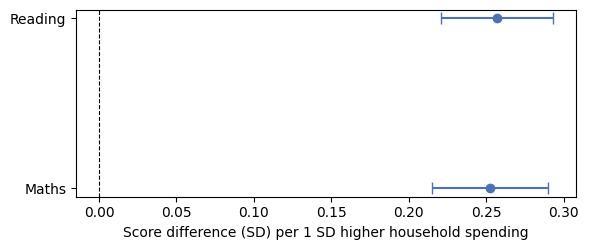

In [54]:
# Convert the regression results list to a DataFrame
reg = pd.DataFrame(results)

# One picture of the main result (Model C)
plot = reg[reg["model"].str.startswith("C")]

fig, ax = plt.subplots(figsize=(6, 2.6))
for i, r in enumerate(plot.itertuples()):
    ax.errorbar(r.effect, i,
                xerr=[[r.effect - r.ci_low], [r.ci_high - r.effect]],
                fmt="o", color="#4C72B0", capsize=4)

ax.set_yticks(range(len(plot)))
ax.set_yticklabels(plot["outcome"])
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Score difference (SD) per 1 SD higher household spending")
plt.tight_layout()
plt.savefig("summary_figure.png", dpi=150)
plt.show()

# Save the summary numbers (this holds no individual-level data)
reg.to_csv("regression_results.csv", index=False)